# 15 · HST vs DESI vs WCC, at one exposure time

A short version of notebook 14. The same 52" x 35" patch of COSMOS in four data sets:

* **HST** ACS F606W (CANDELS) and **DESI** Legacy Surveys DR10 r: the real images;
* **WCC** `zwo:r` simulated with the exposure time of the HST image (its median, from the CANDELS exposure map), as a stack
  of equal frames, built two ways from each of HST and DESI:
  1. **reproject**: the image itself goes into the simulation (`ImageComponent`);
  2. **catalog**: a source catalog goes in, one Sersic per galaxy (extracted from the HST image; Tractor for DESI).

Each part shows the whole patch first and then three example galaxies. Everything is on the WCC pixel grid, in the
same brightness units and with one stretch. The first run downloads the data (several minutes for the HST rows);
everything is cached afterwards. Methods and checks are in notebook 14 and the scripts in `scripts/`.

In [1]:
import os, sys, warnings
import numpy as np
import matplotlib.pyplot as plt
from reproject import reproject_interp
from scipy.ndimage import gaussian_filter

sys.path.insert(0, os.path.abspath("../scripts"))
import legacysurvey_galaxy_mock as lsm
import hst_catalog_mock as hcm
from candels_cutout import fetch_candels_cutout
from wcc_sim import ImageComponent, detector_frame, empty_catalog, simulate_field
from wcc_sim.catalog import query_gaia
from wcc_sim.starflux import REF_MAG, rate_for_ab

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 85}}

## 1. Data and settings

In [2]:
RA, DEC = lsm.COSMOS
SENSORFILTER = "zwo:r"
SHAPE = (2048, 3072)                     # WCC subarray: 51.8" x 34.5"
CACHE = "ls_cache"
N_FRAMES = 6                             # equal frames in the stack

frame = detector_frame(SENSORFILTER, (RA, DEC), shape=SHAPE)
ny, nx = frame.shape
pix = frame.plate_scale_mas / 1000.0
width, height = nx * pix, ny * pix

hst, hst_wcs, hst_zp, _ = fetch_candels_cutout(RA, DEC, width, height, "f606w", cache_dir=CACHE)
hst_exp, *_ = fetch_candels_cutout(RA, DEC, width, height, "f606w", cache_dir=CACHE, kind="exp")
ls, ls_wcs = lsm.fetch_ls_cutout(RA, DEC, 256 * 0.262, band="r", npix=256)

T_EXP = float(np.median(hst_exp))
print(f"patch {width:.1f}\" x {height:.1f}\"; HST median exposure {T_EXP:.0f} s = {T_EXP / 3600:.2f} h "
      f"-> WCC stack of {N_FRAMES} x {T_EXP / N_FRAMES:.0f} s")

patch 51.8" x 34.5"; HST median exposure 5041 s = 1.40 h -> WCC stack of 6 x 840 s


## 2. Real images on the WCC grid, and the four inputs

Surface brightness in nanomaggies per arcsec^2 (HST from its zero point, DESI is already nanomaggies), interpolated onto the
WCC pixels. The **images** are cleaned before use: `ImageComponent` clips negative pixels to zero, which would turn
the positive half of the image noise into frozen sky signal, so only connected regions of detected light are kept.
The **catalogs** are the sources extracted from the HST image (`photutils`, S/N >= 7; Sersic n = 1 unless the ACS ZEST
fit has one) and the DESI Tractor galaxies.

In [3]:
def to_grid(data, wcs):
    out, _ = reproject_interp((data, wcs), frame.wcs, shape_out=frame.shape, order="bilinear")
    return out

hst_sb = to_grid(hst * 10.0 ** (0.4 * (22.5 - hst_zp)) / 0.030**2, hst_wcs)
ls_sb = to_grid(ls / 0.262**2, ls_wcs)
hst_sb, ls_sb = (a - np.nanmedian(a) for a in (hst_sb, ls_sb))

# reproject inputs
comp_hst = ImageComponent(hcm.mask_to_sources(hst), hst_wcs, hst_zp)
comp_ls = ImageComponent(hcm.mask_to_sources(ls, smooth_sigma_px=0.7, dilate_px=1, min_area_px=6), ls_wcs, 22.5)

# catalog inputs
half_diag = 0.5 * np.hypot(nx, ny) * pix
tractor = lsm.fetch_tractor(RA, DEC, half_diag + lsm.QUERY_MARGIN_ARCSEC, cache_dir=CACHE)
sersic_ls, truth = lsm.tractor_to_sersic(tractor, frame, SENSORFILTER)
hst_tab = hcm.detect_hst_sources(hst, hst_wcs, hst_zp, min_snr=7.0)
zest_n = hcm.zest_sersic_n(hst_tab["ra"], hst_tab["dec"], 60, cache_dir=CACHE)
gaia = query_gaia(RA, DEC, half_diag + 10.0, mag_limit=21.0, cache_dir=os.path.join(CACHE, "gaia"))
sersic_hst, _ = hcm.catalog_to_sersic(hst_tab, hst_wcs, frame, SENSORFILTER, n_sersic=zest_n, gaia=gaia)
print(f"catalogs: {len(sersic_hst)} HST-extracted sources, {len(sersic_ls)} Tractor galaxies")

catalogs: 154 HST-extracted sources, 123 Tractor galaxies


## 3. Simulate WCC at the HST exposure time

One call per mock: `exptime` is the total, `n_reads` the number of frames, so the simulator applies Poisson noise on
source, sky and dark, read noise once per frame, and saturation per frame. The reproject mocks switch Gaia off (the stars are in
the images); the catalog mocks keep it.

In [4]:
rate_ref = rate_for_ab(REF_MAG, SENSORFILTER)
def observe(extended, gaia_on, seed):
    f = simulate_field(RA, DEC, sensorfilter=SENSORFILTER, exptime=T_EXP, n_reads=N_FRAMES, shape=SHAPE, seed=seed,
                       extended_sources=extended, catalog=None if gaia_on else empty_catalog(),
                       cache_dir=os.path.join(CACHE, "gaia"))
    nmgy = 10.0 ** (0.4 * (22.5 - REF_MAG)) * (f.image_e / T_EXP) / rate_ref
    sb = nmgy / pix**2
    return sb - np.nanmedian(sb)

wcc = {
    "reproject HST": observe([comp_hst], False, 1),
    "reproject DESI": observe([comp_ls], False, 2),
    "catalog HST": observe(sersic_hst, True, 3),
    "catalog DESI": observe(sersic_ls, True, 4),
}
print("done:", ", ".join(wcc))

done: reproject HST, reproject DESI, catalog HST, catalog DESI


## 4. Zoomed-out and zoomed-in figures

Helpers for the two figure types. The overview stretch is set by the brightest 0.2% of HST pixels and is the same for every
panel. The zooms use the three largest resolved galaxies among the brighter ones in the patch (found from the Tractor
catalog), one stretch per row, and all panels are smoothed lightly for display (sigma = 2 WCC pixels = 34 mas, below the
~50 mas WCC PSF) because a single 1.4 h frame is noisy at the native pixel.

In [5]:
HI = np.nanpercentile(hst_sb, 99.8)
gx, gy = frame.wcs.world_to_pixel_values(truth["ra"], truth["dec"])
inside = (gx > 150) & (gx < nx - 150) & (gy > 150) & (gy < ny - 150)
cand = [i for i in np.argsort(truth["mag_ab_band"]) if inside[i] and truth["r_eff_arcsec"][i] > 0.5][:3]

def overview(panels):
    fig, axes = plt.subplots(2, 2, figsize=(14, 2 * 7.0 * height / width + 0.8))
    for k, (ax, (img, title)) in enumerate(zip(axes.flat, panels)):
        ax.imshow(np.arcsinh(np.nan_to_num(img) / HI * 30.0) / np.arcsinh(30.0), origin="lower", cmap="gray",
                  vmin=-0.05, vmax=1, extent=(0, width, 0, height))
        ax.set_title(title, fontsize=10); ax.set_yticks([])
        if k >= 2:
            ax.set_xlabel("arcsec")
    fig.tight_layout()

def zooms(panels):
    fig, axes = plt.subplots(len(cand), len(panels), figsize=(3.5 * len(panels), 3.5 * len(cand)))
    for row, i in zip(axes, cand):
        h = int(np.clip(4 * truth["r_eff_arcsec"][i], 2.5, 8.0) / pix)
        cx, cy = int(gx[i]), int(gy[i])
        sl = (slice(max(cy - h, 0), cy + h), slice(max(cx - h, 0), cx + h))
        local_hi = np.nanpercentile(hst_sb[sl], 99.5)
        for ax, (img, name) in zip(row, panels):
            cut = gaussian_filter(np.nan_to_num(img), 2.0)[sl]          # display smoothing, ~34 mas
            ax.imshow(np.arcsinh(cut / local_hi * 20.0) / np.arcsinh(20.0), origin="lower", cmap="magma", vmin=-0.05, vmax=1)
            ax.set_xticks([]); ax.set_yticks([]); ax.set_title(name, fontsize=9)
    fig.tight_layout()

T_LABEL = f"{T_EXP / 3600:.1f} h"
PART1 = [(hst_sb, "HST"), (ls_sb, "DESI"), (wcc["reproject HST"], f"WCC {T_LABEL}, from the HST image"),
         (wcc["reproject DESI"], f"WCC {T_LABEL}, from the DESI image")]
PART2 = [(hst_sb, "HST"), (ls_sb, "DESI"), (wcc["catalog HST"], f"WCC {T_LABEL}, from the HST-extracted catalog"),
         (wcc["catalog DESI"], f"WCC {T_LABEL}, from the Tractor (DESI) catalog")]

### Part 1 · reproject: the image goes into the simulation

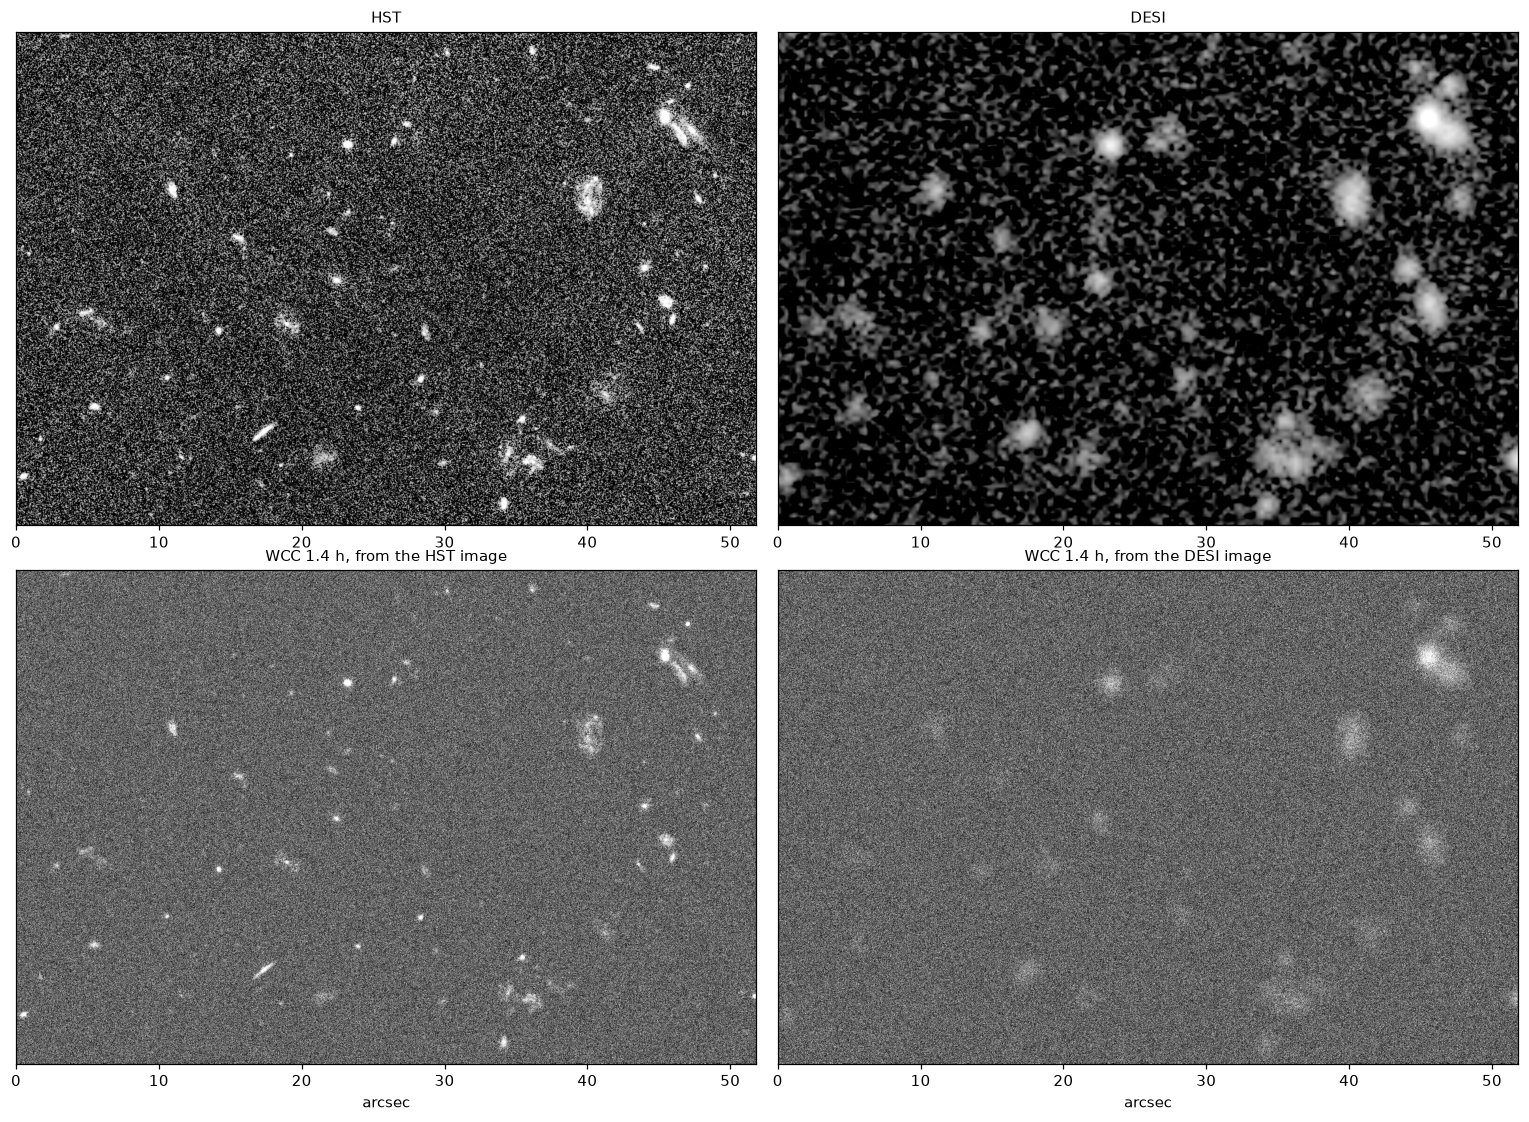

In [6]:
overview(PART1)

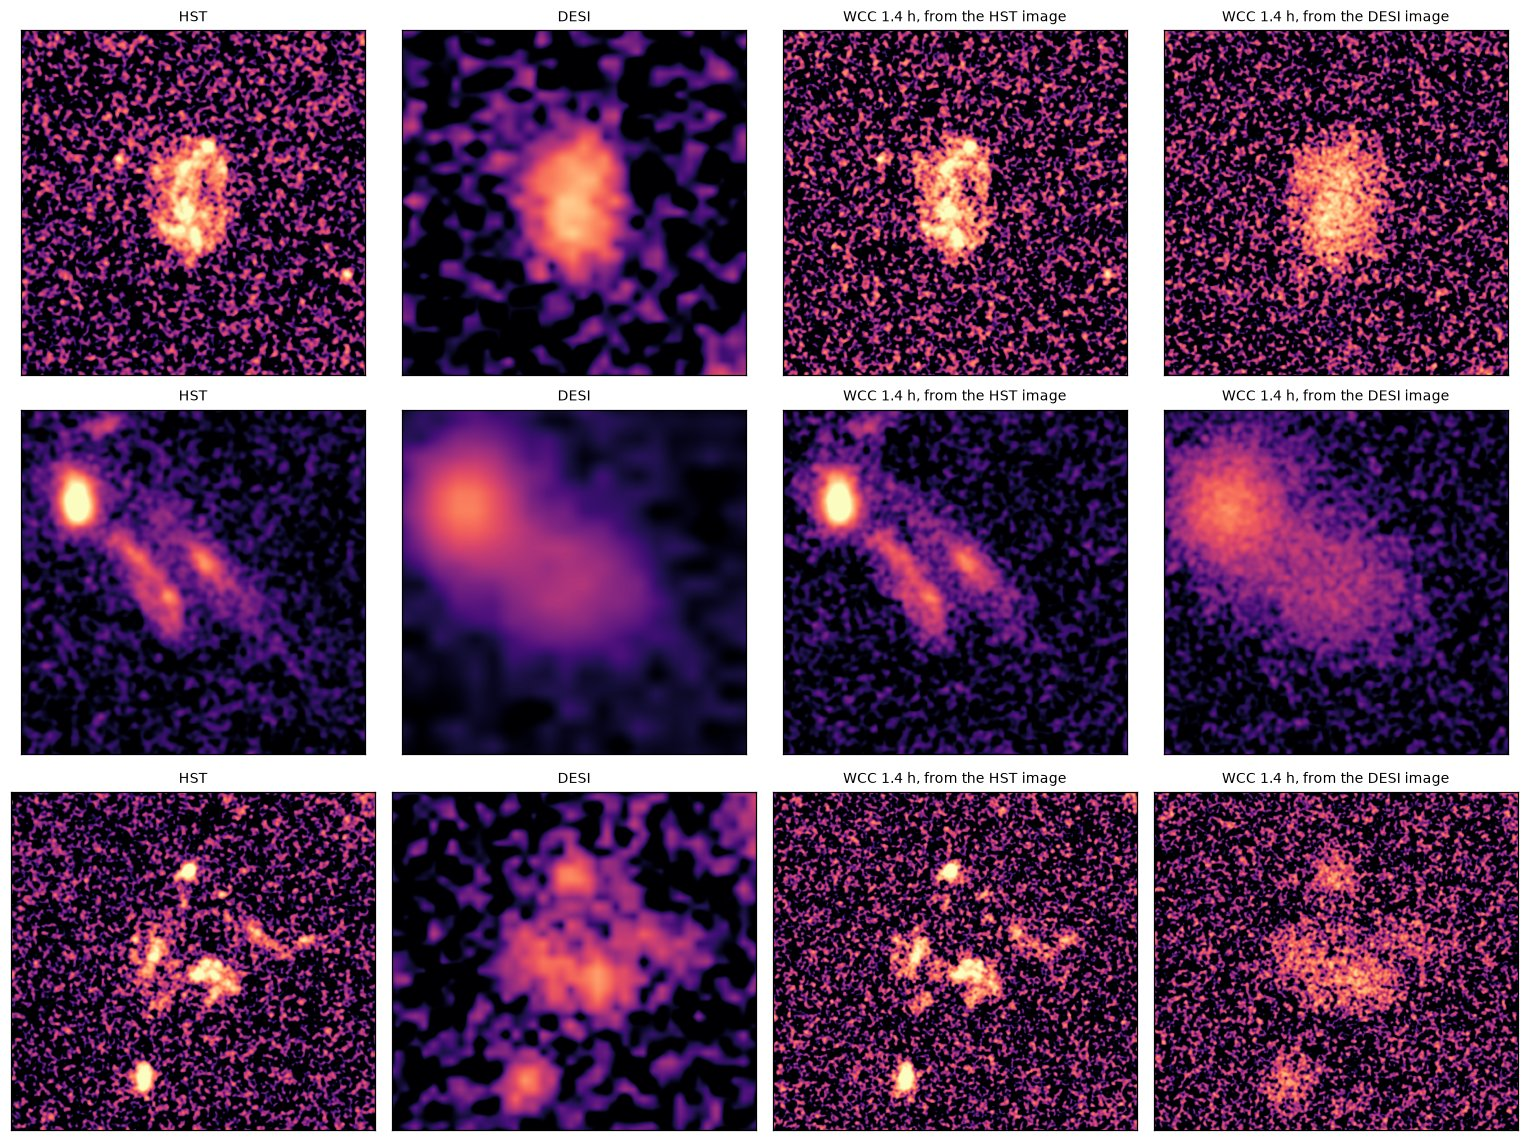

In [7]:
zooms(PART1)

### Part 2 · catalog: a list of Sersic sources goes into the simulation

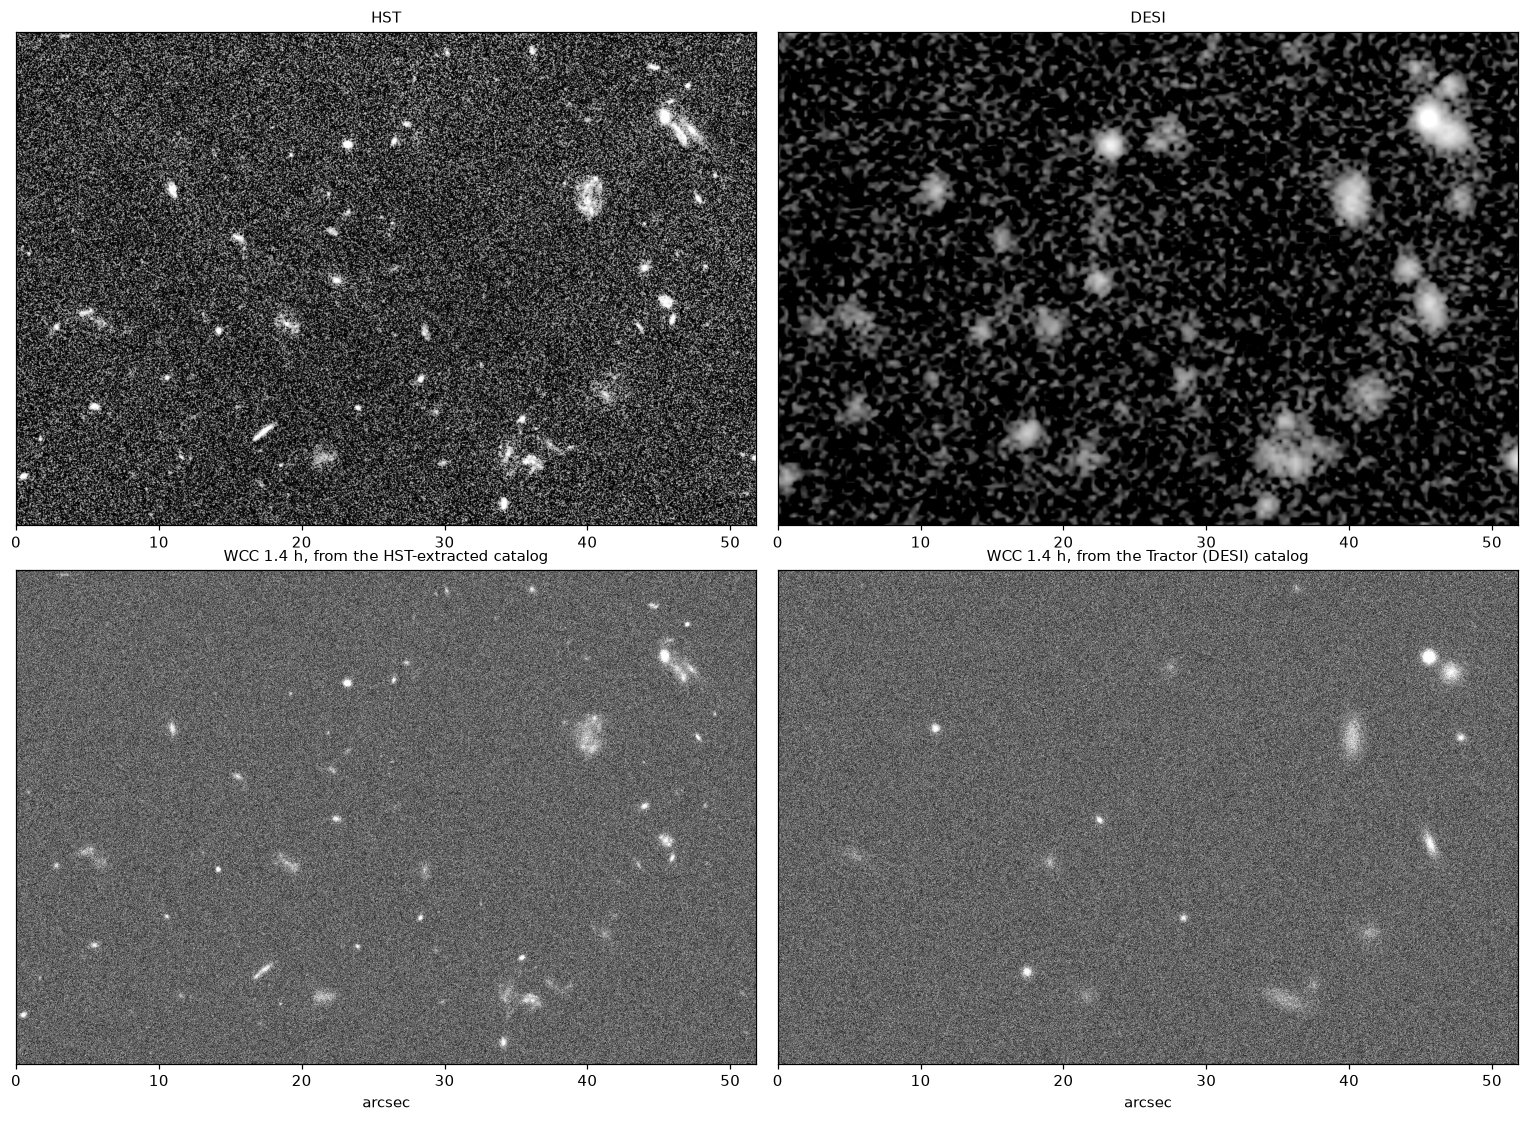

In [8]:
overview(PART2)

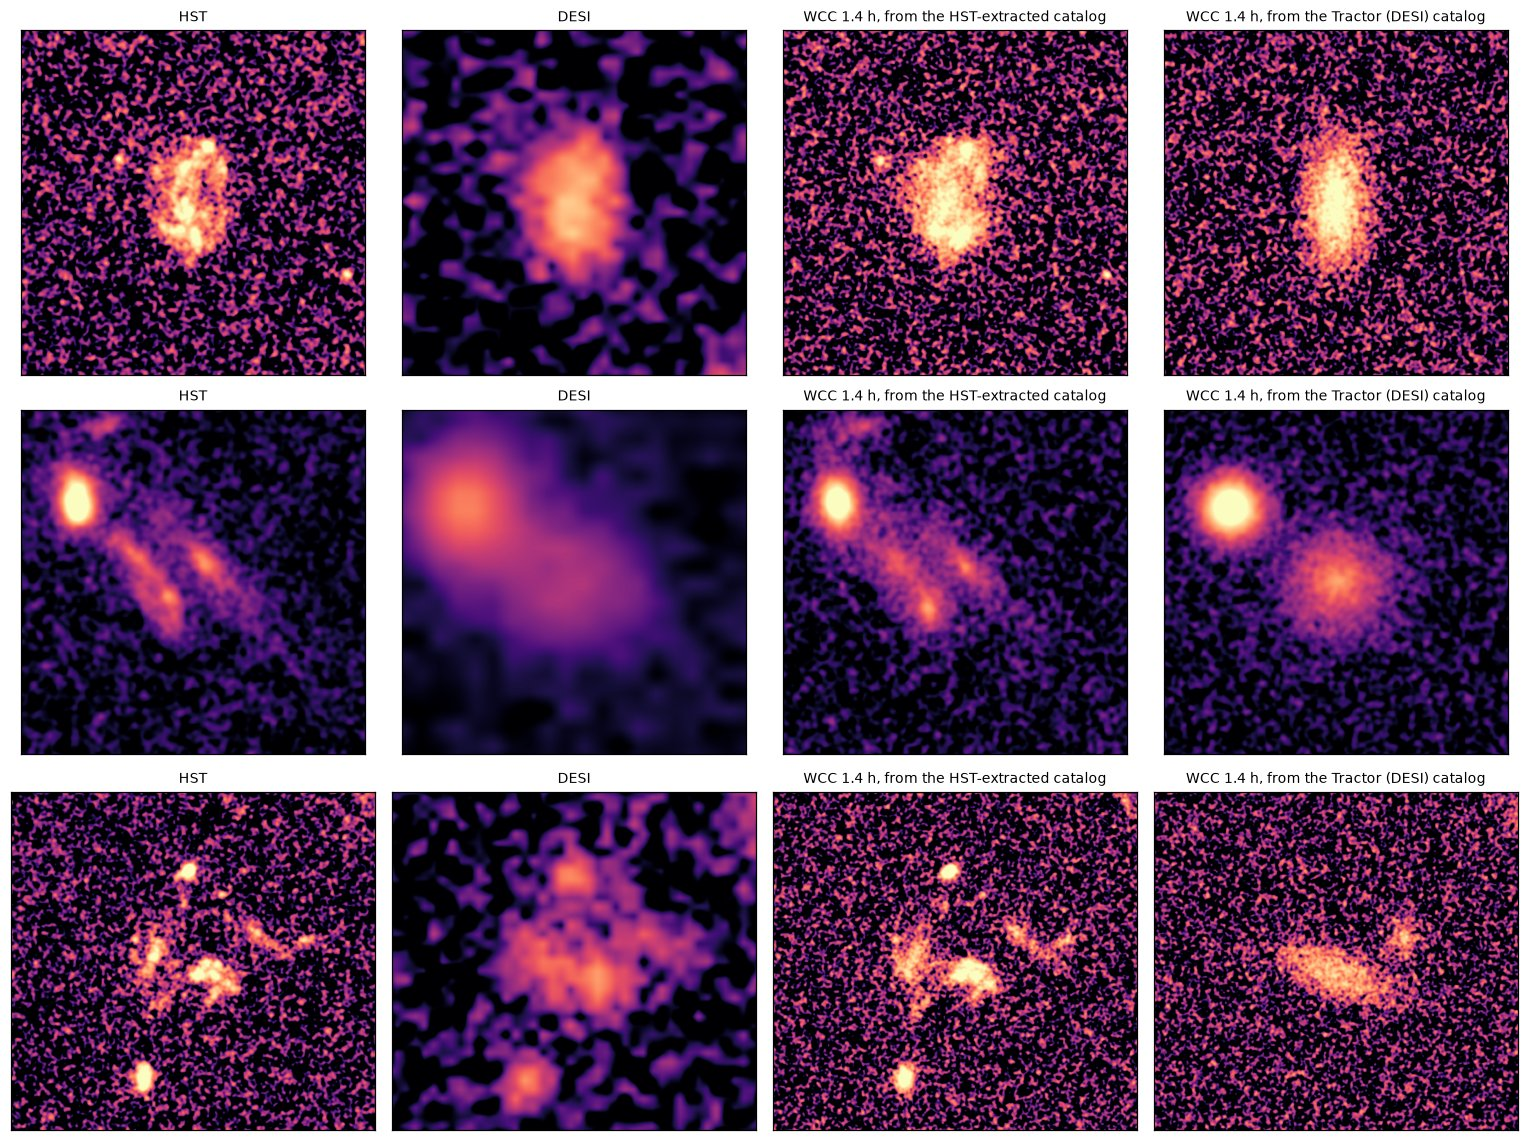

In [9]:
zooms(PART2)

## 5. How close is each WCC mock to the HST image?

Pearson correlation and flux ratio against HST at 0.13" scale (8 x 8 WCC pixels), inside the footprint of the detected HST
light, where the real image has signal (the reproject-from-HST row is close to 1 by construction).

In [10]:
bin8 = lambda a: a[:(a.shape[0] // 8) * 8, :(a.shape[1] // 8) * 8].reshape(a.shape[0] // 8, 8, a.shape[1] // 8, 8).mean(axis=(1, 3))
footprint = bin8(to_grid((comp_hst.data != 0).astype(float), hst_wcs)) > 0.5
ref = bin8(np.nan_to_num(hst_sb))
print(f"{'':20s} {'r':>6s} {'flux / HST':>11s}   ({int(footprint.sum())} boxes)")
for name, img in (("DESI image", ls_sb), *wcc.items()):
    b = bin8(np.nan_to_num(img))
    print(f"{name:20s} {np.corrcoef(ref[footprint], b[footprint])[0, 1]:6.3f} {b[footprint].sum() / ref[footprint].sum():11.3f}")

                          r  flux / HST   (3180 boxes)
DESI image            0.424       0.581
reproject HST         0.987       1.006
reproject DESI        0.366       0.520
catalog HST           0.880       0.998
catalog DESI          0.438       0.647


## Reading the comparison

At this exposure (about 1.4 h, six 840 s frames) the WCC noise per 0.3" box is about 1.1 times HST's (notebook 14,
section 9), so the brighter structure is detected and the faint outskirts are not.

* **Reproject.** The WCC image is the input image seen through the WCC PSF, pixels and noise. From the HST image it keeps
  the knots, arms and arcs (correlation 0.99 with HST in the footprint); from the DESI image it keeps only DESI's soft,
  ~1" blobs (0.37). WCC cannot add detail that is not in the image that goes in.
* **Catalog.** One Sersic per source. The HST-extracted catalog places the clumps of each galaxy as separate sources
  and gets the layout right (0.88, and the flux 1.00); the Tractor catalog gives a smooth ellipse per galaxy (0.44, flux
  0.65), wrong for the round, clumpy galaxy in the first row.
* **Coverage.** Both routes from HST need HST: CANDELS covers about 14' x 36' of COSMOS. The DESI inputs reach most of
  the sky but carry its 1" resolution, so they bound what a WCC mock can show of substructure; the HST-based mocks
  are the better truth where they exist.

All four WCC mocks include noise, which lowers the correlations a little. The mocks are built from the HST or DESI
data themselves, so the HST-based ones resemble HST by construction: they show what WCC's PSF, pixels and noise do to
an HST-like sky, not whether WCC would recover structure it has to find on its own.

## Optional: how the HST source catalog was made

*Not needed to run anything above.* The "HST-extracted catalog" of Part 2 is **not a published CANDELS catalog**. It was
extracted from the CANDELS F606W cutout shown above with `photutils`, and `scripts/hst_catalog_mock.py` wraps these steps
(`detect_hst_sources`, then `catalog_to_sersic`). They are written out here so the choices can be seen and changed:

1. subtract the background, smooth with a 3-pixel FWHM Gaussian, and detect regions of at least 15 connected pixels above
   3 sigma of the smoothed image, then deblend;
2. measure each source: Kron flux (AB magnitude and S/N), half-light radius, second-moment ellipticity and angle; keep S/N >= 7;
3. turn each into a single Sersic: the circular half-light radius becomes a semi-major one, the HST PSF is removed in
   quadrature, the HST pixel angle is carried through the sky to the WCC detector, and the AB magnitude becomes the
   Gaia-G-equivalent the simulator takes; n = 1 except where the ACS ZEST (GIM2D) fit has an index.

In [11]:
from astropy.convolution import Gaussian2DKernel, convolve
from astropy.stats import gaussian_fwhm_to_sigma, sigma_clipped_stats
from photutils.background import Background2D, MedianBackground
from photutils.segmentation import SourceCatalog, deblend_sources, detect_sources

# 1. detection
img = hst - Background2D(hst, (64, 64), filter_size=(3, 3), bkg_estimator=MedianBackground()).background
_, _, sigma = sigma_clipped_stats(img, sigma=3)                              # pixel noise, e-/s
smooth = convolve(img, Gaussian2DKernel(3.0 * gaussian_fwhm_to_sigma, x_size=11, y_size=11), normalize_kernel=True)
_, _, sigma_smooth = sigma_clipped_stats(smooth, sigma=3)
segm = detect_sources(smooth, 3.0 * sigma_smooth, npixels=15)                # >= 15 pixels above 3 sigma
segm = deblend_sources(smooth, segm, npixels=15, nlevels=32, contrast=0.05, progress_bar=False)
cat = SourceCatalog(img, segm, convolved_data=smooth, error=np.full_like(img, sigma))

# 2. measurement and S/N cut
snr = np.asarray(cat.kron_flux / cat.kron_flux_err)
mag_ab = hst_zp - 2.5 * np.log10(np.asarray(cat.kron_flux))
r_circ = np.asarray(cat.fluxfrac_radius(0.5)) * 0.030                       # circle holding half the light, arcsec
ellip_x = 1.0 - np.asarray(cat.semiminor_sigma.value) / np.asarray(cat.semimajor_sigma.value)
theta = np.asarray(cat.orientation.to_value("deg"))                         # major axis, CCW from +x of the image
good = np.isfinite(mag_ab) & np.isfinite(snr) & (snr >= 7) & np.isfinite(ellip_x) & np.isfinite(r_circ) & (r_circ > 0)
print(f"{segm.nlabels} segments after deblending -> {int(good.sum())} with S/N >= 7")

188 segments after deblending -> 157 with S/N >= 7


In [12]:
# 3. one Sersic per source
from astropy import units as u
from astropy.coordinates import SkyCoord
from wcc_sim.starflux import rate_for_spt

xc, yc = np.asarray(cat.xcentroid)[good], np.asarray(cat.ycentroid)[good]
q = 1.0 - np.clip(ellip_x[good], 0.0, lsm.MAX_ELLIP)
r_major = r_circ[good] / np.sqrt(q)                                           # circular -> semi-major half-light radius
r_eff = np.clip(np.sqrt(np.clip(r_major**2 - hcm.HST_PSF_R_HALF_ARCSEC**2, 0, None)), hcm.MIN_R_EFF_ARCSEC, None)

ra_x, dec_x = hst_wcs.pixel_to_world_values(xc, yc)
tx = np.radians(theta[good])
p0 = SkyCoord(*hst_wcs.pixel_to_world_values(xc, yc), unit="deg")
p1 = SkyCoord(*hst_wcs.pixel_to_world_values(xc + np.cos(tx), yc + np.sin(tx)), unit="deg")
pa_sky = p0.position_angle(p1).deg % 180.0                                    # HST pixel angle -> E of N
pa_wcc = lsm.pixel_position_angle(frame, ra_x, dec_x, pa_sky)                 # -> angle on the WCC detector

g_equiv = REF_MAG - 2.5 * np.log10(np.array([rate_for_ab(m, SENSORFILTER) for m in mag_ab[good]]) / rate_for_spt("G2V", SENSORFILTER))

# check against the catalog used above (same detection, before the edge and Gaia-star cuts)
same = (len(hst_tab) == int(good.sum())) and np.allclose(hst_tab["mag_ab"], mag_ab[good]) \
    and np.allclose(hst_tab["r_circ_arcsec"], r_circ[good]) and np.allclose(hst_tab["ellip"], ellip_x[good])
print("reproduces the catalog used above:", same)

order = np.argsort(mag_ab[good])[:6]
print(f"\nthe six brightest sources: Sersic parameters passed to the simulator (n = 1 unless ZEST has one)")
print(f"{'RA':>10s} {'Dec':>9s} {'AB mag':>7s} {'r_eff\"':>7s} {'ellip':>6s} {'PA(WCC)':>8s} {'G-equiv':>8s}")
for i in order:
    print(f"{ra_x[i]:10.5f} {dec_x[i]:9.5f} {mag_ab[good][i]:7.2f} {r_eff[i]:7.3f} {1 - q[i]:6.2f} {pa_wcc[i]:8.1f} {g_equiv[i]:8.2f}")

reproduces the catalog used above: True

the six brightest sources: Sersic parameters passed to the simulator (n = 1 unless ZEST has one)
        RA       Dec  AB mag  r_eff"  ellip  PA(WCC)  G-equiv
 150.11458   2.20313   23.09   0.209   0.31     98.3    23.07
 150.12076   2.20260   23.94   0.127   0.14    173.2    23.92
 150.11406   2.20288   23.99   1.193   0.71    133.1    23.98
 150.11433   2.20288   24.24   0.652   0.49    126.4    24.23
 150.11606   2.20149   24.43   0.756   0.49    153.4    24.41
 150.12236   2.19704   24.52   0.521   0.70     37.0    24.51


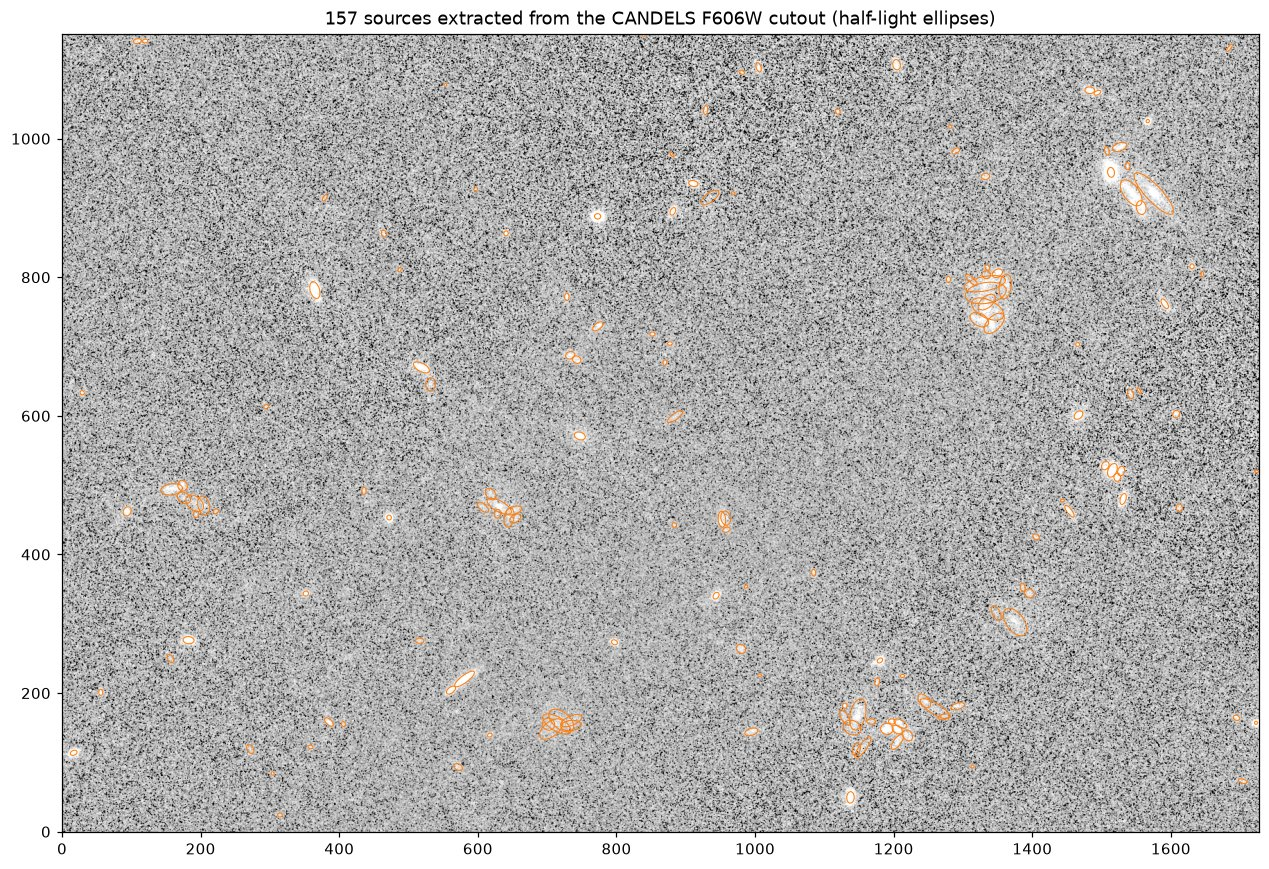

In [13]:
# the measured half-light ellipses on the HST image
from matplotlib.patches import Ellipse
fig, ax = plt.subplots(figsize=(12, 12 * hst.shape[0] / hst.shape[1]))
lo_, hi_ = np.percentile(hst, [5, 99.7])
ax.imshow(np.arcsinh((hst - lo_) / (hi_ - lo_) * 40) / np.arcsinh(40), origin="lower", cmap="gray", vmin=0, vmax=1)
for x_, y_, qq, rc, th in zip(xc, yc, q, r_circ[good], theta[good]):
    rm = rc / np.sqrt(qq) / 0.030
    ax.add_patch(Ellipse((x_, y_), 2 * rm, 2 * rm * qq, angle=th, fill=False, ec="C1", lw=0.7))
ax.set_title(f"{len(xc)} sources extracted from the CANDELS F606W cutout (half-light ellipses)")
fig.tight_layout()

The step that follows in `catalog_to_sersic` is bookkeeping: sources that touch the edge of the cutout are dropped (cut off),
and so are those within 0.5" of a Gaia star (the simulator already draws those). To change the catalog, edit the thresholds
above (3 sigma, 15 pixels, S/N >= 7, deblending contrast) or the PSF size and minimum radius in `hst_catalog_mock.py`; the
number of sources, and how finely clumpy galaxies are split into pieces, change most.